# Operation-count extrapolation in the five-slot identity format — train k ∈ {0, 2, 3, 4}, held out k ∈ {1, 5}

Transformer AR and Looped AR only, configured exactly as in the successful identity_02345 run (notebook 10). Every
instruction has FIVE visible operation tokens: k A/B/C tokens in random ordered slots, with the other 5-k slots
filled by the learnable `<identity>` token. There is no PAD.

* **Extrapolation is in k**, the number of non-identity operations, NOT in sequence length or position indices. The
  AR sequence is always 82 tokens.
* **Budget:** seed 42, 5000 updates x 256 = 1,280,000 records. Allocation: 64 per k per update (320,000 each). Within k, words and slot subsets
  are uniform.
* **Selection:** validation uses ONLY the trained k (300 grids each); singletons and held-out k never influence
  selection.
* **Test:** the shared notebook-10 manifest (376,000 records, including all 15 singleton placements). AR decoding is
  free-running.
* **Comparing 12, 13 and 14:** they have the same total budget but different per-k exposure (each larger support
  replaces some exposure of the smaller k). Initial weights are identical per architecture across all three.
* **Post-hoc analyses:**
  * training-transformation coverage, since a held-out word can still induce a seen transformation;
  * the even-count ambiguity: with H = shift (3,3), H∘A, H∘B, H∘C reproduce every even-k mapping exactly, so train02
    data alone cannot rule this alternative out, and k = 3 supervision rejects it.

One seed: descriptive only.


In [1]:
# --- 2. Bootstrap: locate or clone the PRIVATE repository (credentials are never printed or stored) ---
import base64, importlib.util, os, pathlib, subprocess, sys

REPO_URL = "https://github.com/zhexuandliu/Decompositionality.git"
REPO_BRANCH = "main"
IN_COLAB = "google.colab" in sys.modules or "COLAB_RELEASE_TAG" in os.environ

def _find_repo():
    candidates = [pathlib.Path("/content/Decompositionality"), pathlib.Path.cwd(), *pathlib.Path.cwd().parents]
    for p in candidates:
        if (p / "src" / "decompositionality").is_dir():
            return p.resolve()
    return None

REPO_DIR = _find_repo()
if REPO_DIR is None:
    token = None
    if IN_COLAB:
        try:
            from google.colab import userdata
            token = userdata.get("GITHUB_TOKEN")
        except Exception:
            token = None
    if not token:
        import getpass
        token = getpass.getpass("GitHub token with read access to the private repo (input hidden): ")
    # Pass the credential through environment-scoped git config (not the URL, not the command line,
    # not persisted in .git/config).
    _hdr = "AUTHORIZATION: basic " + base64.b64encode(f"x-access-token:{token}".encode()).decode()
    _env = dict(os.environ, GIT_TERMINAL_PROMPT="0", GIT_CONFIG_COUNT="1",
                GIT_CONFIG_KEY_0="http.https://github.com/.extraheader", GIT_CONFIG_VALUE_0=_hdr)
    REPO_DIR = pathlib.Path("/content/Decompositionality" if IN_COLAB else "Decompositionality").resolve()
    _r = subprocess.run(["git", "clone", "--depth", "1", "--branch", REPO_BRANCH, REPO_URL, str(REPO_DIR)],
                        env=_env, capture_output=True, text=True)
    del token, _hdr, _env
    if _r.returncode != 0:
        raise RuntimeError("git clone failed (check the GITHUB_TOKEN secret / repo access):\n" + _r.stderr[-2000:])

if str(REPO_DIR / "src") not in sys.path:
    sys.path.insert(0, str(REPO_DIR / "src"))
for _mod in ("numpy", "pandas", "matplotlib", "torch"):
    if importlib.util.find_spec(_mod) is None:  # Colab already ships these; never reinstall torch/CUDA here
        subprocess.run([sys.executable, "-m", "pip", "install", "-q", _mod], check=True)
REPO_COMMIT = subprocess.run(["git", "-C", str(REPO_DIR), "rev-parse", "HEAD"], capture_output=True, text=True).stdout.strip()
print("Repository:", REPO_DIR, "| commit:", REPO_COMMIT or "unknown")


Repository: /content/Decompositionality | commit: 280ee70919d0b36d3ed574d5bee9f5205be6c104


In [2]:
# --- CONFIGURATION (the only cell to edit) --------------------------------------------------------------------
EXPERIMENT = "idext_train0234"            # fixed for this notebook
MODE = os.environ.get("DECOMP_MODE", "full")   # "full" | "smoke" (tiny CPU check, separate paths, NOT results)
SEED = int(os.environ.get("DECOMP_SEED", 42))  # configurable for later replication; no automatic seed sweep
MODELS = ["transformer_ar", "looped_transformer_ar"]
USE_DRIVE = IN_COLAB
RESULTS_ROOT = os.environ.get("DECOMP_RESULTS_ROOT") or (
    "/content/drive/MyDrive/decompositionality_results" if USE_DRIVE
    else "/content/decompositionality_results" if IN_COLAB else str(REPO_DIR / "results"))
EXT_ROOT = f"{RESULTS_ROOT}/identity_ar_count_extrapolation"
RESUME = True
DEVICE = os.environ.get("DECOMP_DEVICE", "auto")
DTYPE = "auto"
MICROBATCH = None
EVAL_CHUNK_GRIDS = 100
# -----------------------------------------------------------------------------------------------------------------
if USE_DRIVE and IN_COLAB and RESULTS_ROOT.startswith("/content/drive"):
    from google.colab import drive
    drive.mount("/content/drive")
from decompositionality.config import make_experiment_config
from decompositionality import idext as E
cfg = make_experiment_config(EXPERIMENT, MODE, EXT_ROOT, MODELS, seed=SEED, device=DEVICE, dtype=DTYPE,
                             microbatch_size=MICROBATCH)
cfg.resume = RESUME
FAMILY_ROOT = cfg.manifest_dir.parent
expected = dict(lr=3e-4, weight_decay=0.01, warmup_steps=250, min_lr=3e-5, grad_clip=1.0, val_every=250)
print("resolved recipe:", cfg.train.semantic_dict())
print("discrepancies from expected:", {k: (getattr(cfg.train, k), v) for k, v in expected.items() if getattr(cfg.train, k) != v} or "none")
if MODE == "smoke":
    print("*** SMOKE MODE: tiny integration run; NOT scientific results ***")
print(f"{EXPERIMENT}: train k={list(E.train_ks(EXPERIMENT))} | steps={cfg.train.optimizer_steps} | batch={cfg.train.effective_batch_size}"
      f" | seed={SEED} | runs -> {cfg.experiment_dir}")


Mounted at /content/drive
resolved recipe: {'seed': 42, 'optimizer_steps': 5000, 'effective_batch_size': 256, 'lr': 0.0003, 'min_lr': 3e-05, 'weight_decay': 0.01, 'betas': [0.9, 0.95], 'warmup_steps': 250, 'grad_clip': 1.0, 'val_every': 250}
discrepancies from expected: none
idext_train0234: train k=[0, 2, 3, 4] | steps=5000 | batch=256 | seed=42 | runs -> /content/drive/MyDrive/decompositionality_results/identity_ar_count_extrapolation/train0234/seed_42


In [3]:
import json, torch
from decompositionality.utils import environment_info
print(json.dumps(environment_info(REPO_DIR), indent=1))


{
 "python": "3.13.16",
 "platform": "Linux-6.6.159+-x86_64-with-glibc2.39",
 "torch": "2.14.1+cu130",
 "numpy": "2.4.6",
 "cuda_available": true,
 "repo_commit": "280ee70919d0b36d3ed574d5bee9f5205be6c104",
 "pandas": "2.2.3",
 "matplotlib": "3.10.0",
 "gpu": "NVIDIA A100-SXM4-40GB",
 "cuda": "13.0",
 "bf16_supported": true,
 "gpu_total_memory_gb": 39.49
}


In [4]:
# --- Audits: supports, allocation, serialization, initialization, transformation coverage, H ambiguity -----------
import pandas as pd
from IPython.display import Image, Markdown, display
from decompositionality.idext_reports import (allocation_audit, h_ambiguity_check, init_audit, prepare_idext,
                                              serialization_audit, transformation_coverage)
AUD = cfg.experiment_dir / "audits"; AUD.mkdir(parents=True, exist_ok=True)
print(E.check_supports())
for name, df in (("sample_allocation", allocation_audit(cfg.train.effective_batch_size, cfg.train.optimizer_steps)),
                 ("serialization", serialization_audit()), ("initialization", init_audit(SEED))):
    display(df); df.to_csv(AUD / f"{name}.csv", index=False)
cov, cov_summ = transformation_coverage(); display(cov_summ)
print(h_ambiguity_check())
ctx = prepare_idext(cfg, repo_dir=str(REPO_DIR), legacy_manifest=f"{RESULTS_ROOT}/distinct_pairs/manifests/manifest.json",
                    idvar_manifest=f"{RESULTS_ROOT}/identity_varlen_02345_all_models/manifests/manifest.json")


{'idext_train02': {'logical_words': 10, 'physical_patterns': 91}, 'idext_train023': {'logical_words': 37, 'physical_patterns': 361}, 'idext_train0234': {'logical_words': 118, 'physical_patterns': 766}}


,experiment,k,status,records_update_0,records_full_run,logical_words,five_slot_patterns
0,idext_train02,0,train,128,640000,1,1
1,idext_train02,1,HELD OUT,0,0,3,15
2,idext_train02,2,train,128,640000,9,90
3,idext_train02,3,HELD OUT,0,0,27,270
4,idext_train02,4,HELD OUT,0,0,81,405
5,idext_train02,5,HELD OUT,0,0,243,243
6,idext_train023,0,train,86,426667,1,1
7,idext_train023,1,HELD OUT,0,0,3,15
8,idext_train023,2,train,85,426667,9,90
9,idext_train023,3,train,85,426666,27,270


,word,k,op_tokens,teacher_forced_tokens,output_index,answer_span,eos_index
0,EMPTY,0,I I I I I,82,44,45..80,81
1,A,1,I A I I I,82,44,45..80,81
2,AB,2,A I B I I,82,44,45..80,81
3,ACB,3,I A C I B,82,44,45..80,81
4,ABCA,4,A B I C A,82,44,45..80,81
5,ABCAB,5,A B C A B,82,44,45..80,81


,model,unique_params,identical_initial_state_across_all_supports,init_sha256
0,transformer_ar,10702868,True,c8b91d15761a5cee
1,looped_transformer_ar,1830548,True,804df113d0758967


,experiment,k,seen_transform_words,words
0,idext_train02,0,1,1
1,idext_train02,1,0,3
2,idext_train02,2,9,9
3,idext_train02,3,0,27
4,idext_train02,4,38,81
5,idext_train02,5,0,243
6,idext_train023,0,1,1
7,idext_train023,1,3,3
8,idext_train023,2,9,9
9,idext_train023,3,27,27


{'H': 'shift 3 rows and 3 columns', 'involution': True, 'commutes_with_A_B_C': True, 'tilde_equals_truth_iff_k_even': True, 'words_checked': 364}
[idext_train0234] manifests /content/drive/MyDrive/decompositionality_results/identity_ar_count_extrapolation/manifests (hash bdf24c327a65; {'legacy': 'identical', 'identity_02345 (notebook 10)': 'identical'}) | validation 1200 (k=[0, 2, 3, 4]) | test 376,000


In [5]:
# --- Train both AR models sequentially (fresh identical init per architecture; resumable) -----------------------
from decompositionality.training import train_model
from decompositionality.utils import free_memory
failures = {}
for mid in cfg.models:
    print(f"\n=== training {EXPERIMENT}/{mid} ===")
    try:
        train_model(mid, cfg, ctx.manifests, ctx.val_set, ctx.subset_set, repo_dir=str(REPO_DIR))
    except Exception as exc:
        import traceback; traceback.print_exc(); failures[mid] = repr(exc)
    finally:
        free_memory()
if failures:
    print("TRAINING FAILED:", failures, "-> rerun to resume")



=== training idext_train0234/transformer_ar ===
  microbatch probe: 256 fits
[transformer_ar] 10,702,868 params | device NVIDIA A100-SXM4-40GB | dtype bf16 | microbatch 256 x accumulation 1 = 256
  step 200/5000 loss 1.5563 lr 2.40e-04 | 9.95 steps/s, 2547 ex/s | ETA 8.0 min
  [val @ 250] cell CE 1.4429 (best) | subset(128) exact 0.266 cell 0.426
  step 400/5000 loss 1.1336 lr 2.99e-04 | 9.66 steps/s, 2472 ex/s | ETA 7.9 min
  [val @ 500] cell CE 1.0459 (best) | subset(128) exact 0.281 cell 0.473
  step 600/5000 loss 0.9235 lr 2.96e-04 | 9.62 steps/s, 2462 ex/s | ETA 7.6 min
  [val @ 750] cell CE 0.7028 (best) | subset(128) exact 0.289 cell 0.574
  step 800/5000 loss 0.6533 lr 2.91e-04 | 9.59 steps/s, 2454 ex/s | ETA 7.3 min
  [val @ 1000] cell CE 0.3425 (best) | subset(128) exact 0.391 cell 0.744
  step 1025/5000 loss 0.3041 lr 2.83e-04 | 9.58 steps/s, 2453 ex/s | ETA 6.9 min
  step 1250/5000 loss 0.0341 lr 2.72e-04 | 9.71 steps/s, 2487 ex/s | ETA 6.4 min
  [val @ 1250] cell CE 0.041

In [6]:
# --- Free-running evaluation of the SELECTED checkpoints on the common 376,000-record test manifest -------------
from decompositionality.idvar_pipeline import evaluate_idvar_model, audit_predictions
from decompositionality.idext_reports import build_index
for mid in cfg.models:
    try:
        evaluate_idvar_model(mid, ctx, chunk_grids=EVAL_CHUNK_GRIDS)
    except Exception as exc:
        import traceback; traceback.print_exc()
    finally:
        free_memory()
idx = build_index(FAMILY_ROOT)
aud = pd.DataFrame([{"model": m, **audit_predictions(pathlib.Path(idx[f"{EXPERIMENT}/seed_{SEED}/{m}"]["predictions"]),
                                                     "identity", ctx.manifests.test_grids)}
                    for m in cfg.models if idx.get(f"{EXPERIMENT}/seed_{SEED}/{m}", {}).get("complete")])
display(aud); aud.to_csv(AUD / "prediction_audit.csv", index=False)


  [identity/transformer_ar] chunk 1/10 (37,600 records) | 0.5 min
  [identity/transformer_ar] chunk 2/10 (37,600 records) | 0.9 min
  [identity/transformer_ar] chunk 3/10 (37,600 records) | 1.4 min
  [identity/transformer_ar] chunk 4/10 (37,600 records) | 1.8 min
  [identity/transformer_ar] chunk 5/10 (37,600 records) | 2.3 min
  [identity/transformer_ar] chunk 6/10 (37,600 records) | 2.7 min
  [identity/transformer_ar] chunk 7/10 (37,600 records) | 3.2 min
  [identity/transformer_ar] chunk 8/10 (37,600 records) | 3.6 min
  [identity/transformer_ar] chunk 9/10 (37,600 records) | 4.1 min
  [identity/transformer_ar] chunk 10/10 (37,600 records) | 4.6 min
[identity/transformer_ar] step 5000 | singletons exact A=278/5000 B=3518/5000 C=0/5000 | EMPTY 1.0000 | eval 4.6 min
  [identity/looped_transformer_ar] chunk 1/10 (37,600 records) | 0.5 min
  [identity/looped_transformer_ar] chunk 2/10 (37,600 records) | 0.9 min
  [identity/looped_transformer_ar] chunk 3/10 (37,600 records) | 1.4 min
  [

,model,condition,n_records,expected_records,duplicate_keys,target_oracle_mismatches,prediction_values_out_of_range,invalid_records,k1_records,singleton_records,k_field_mismatches,op_input_length_mismatches,stored_exact_mismatch,input_manifest_mismatches,perfect_predictor_all_100pct,ok
0,transformer_ar,identity,376000,376000,0,0,0,0,15000,15000,0,0,0,0,True,True
1,looped_transformer_ar,identity,376000,376000,0,0,0,0,15000,15000,0,0,0,0,True,True


Run status: idext_train02/transformer_ar: not yet available; idext_train02/looped_transformer_ar: not yet available; idext_train023/transformer_ar: analysed; idext_train023/looped_transformer_ar: analysed; idext_train0234/transformer_ar: analysed; idext_train0234/looped_transformer_ar: analysed


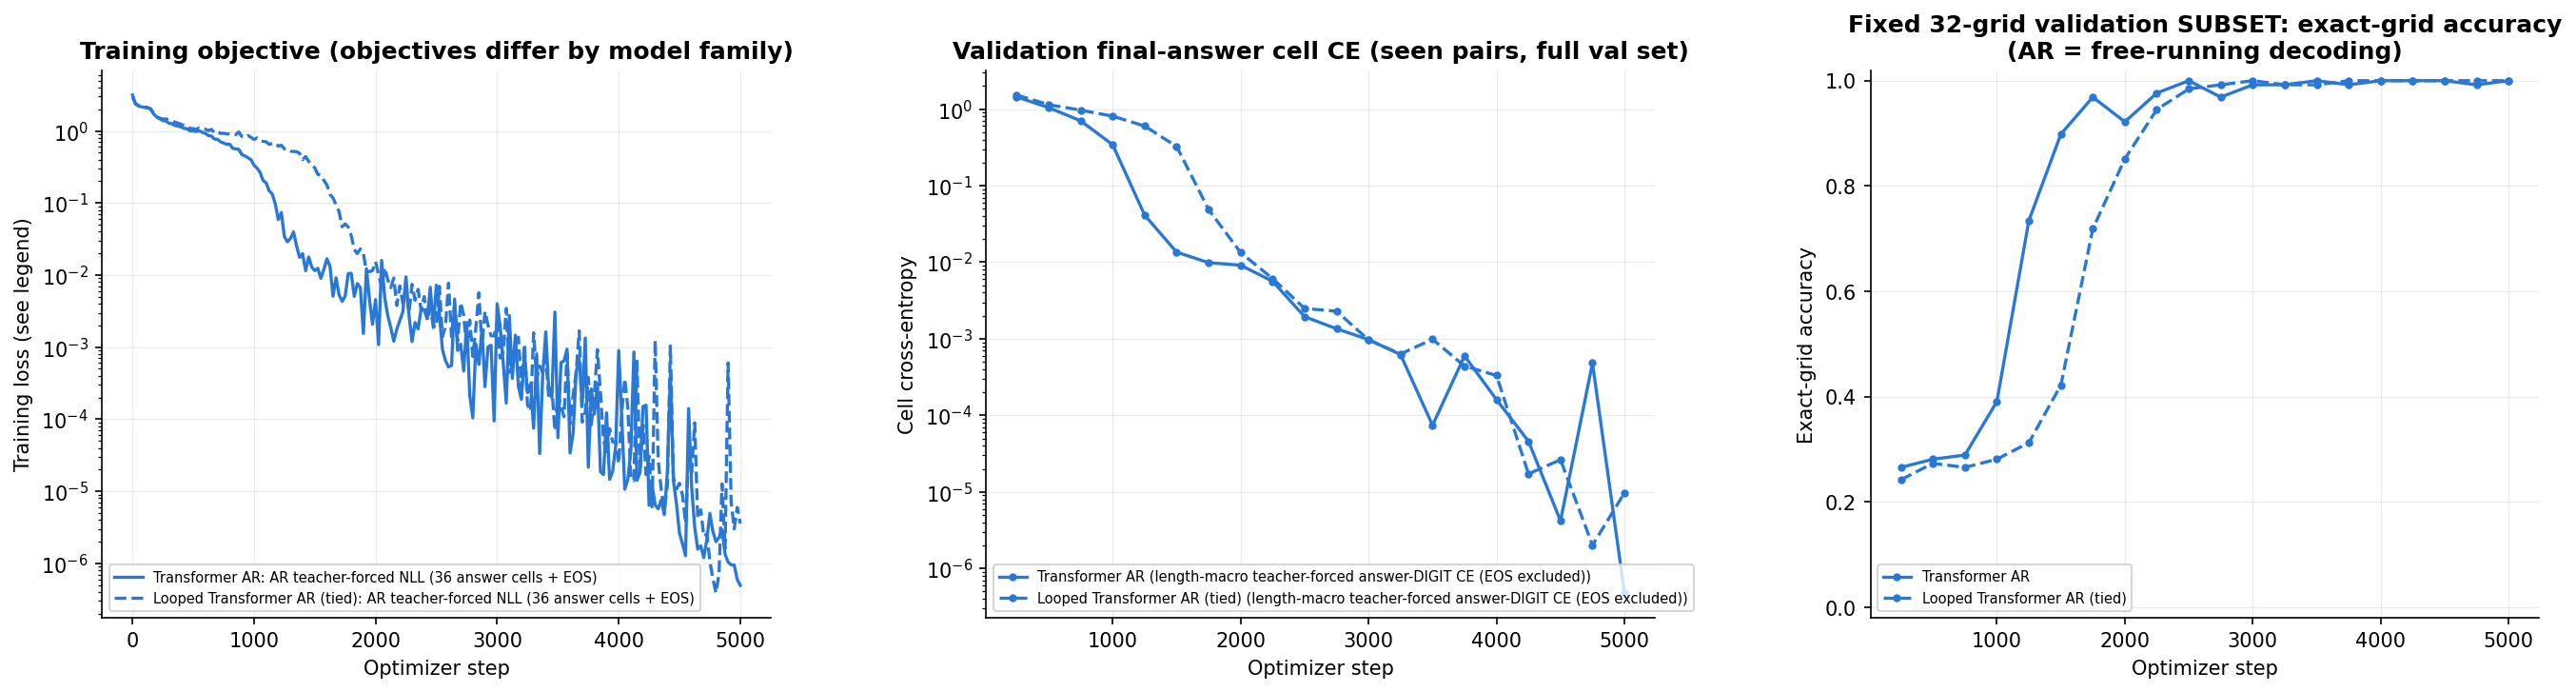

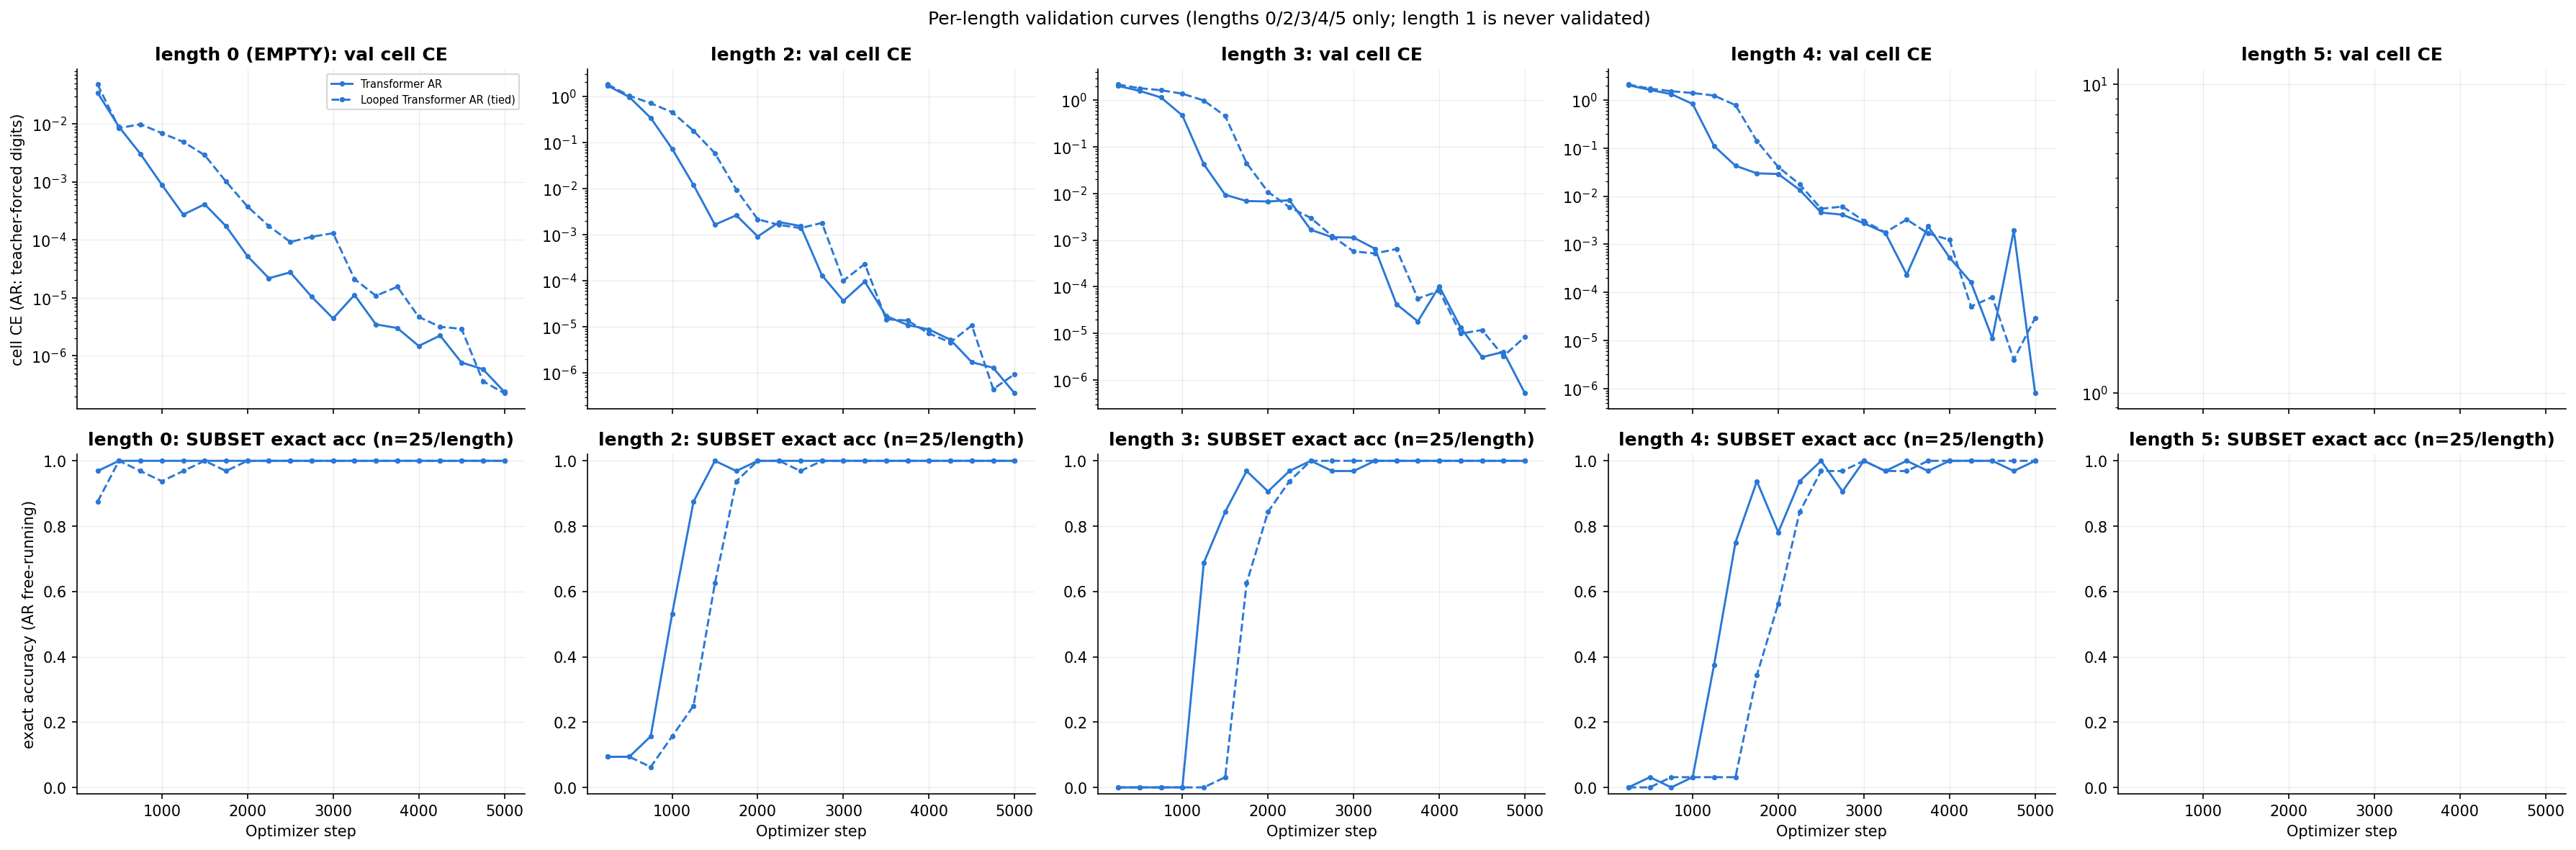

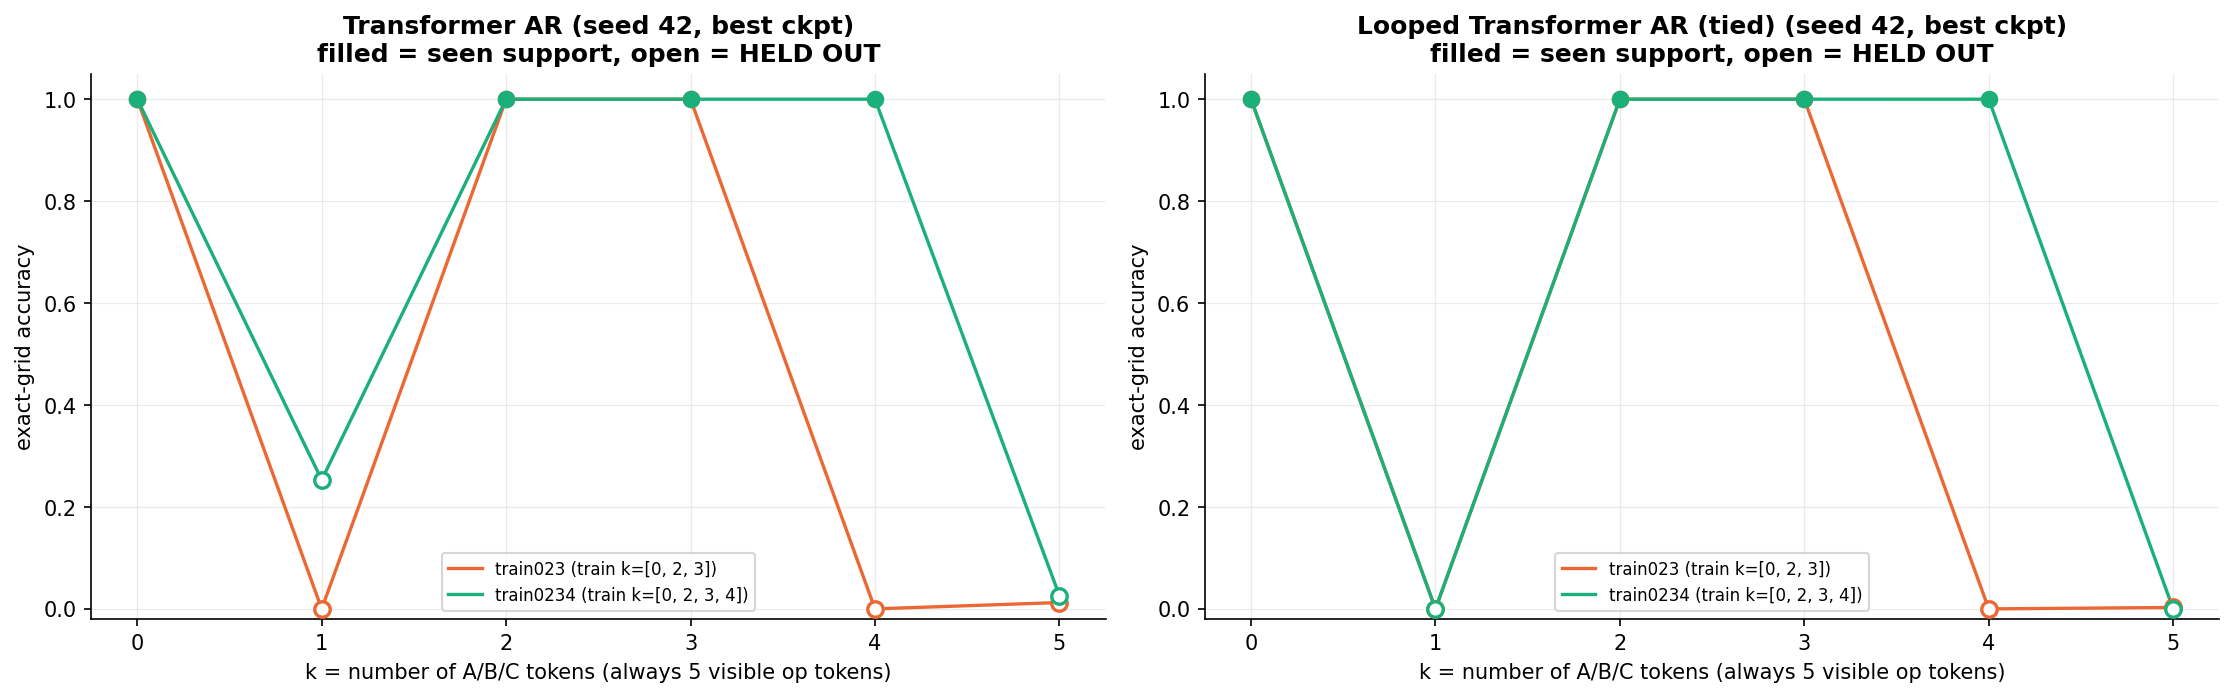

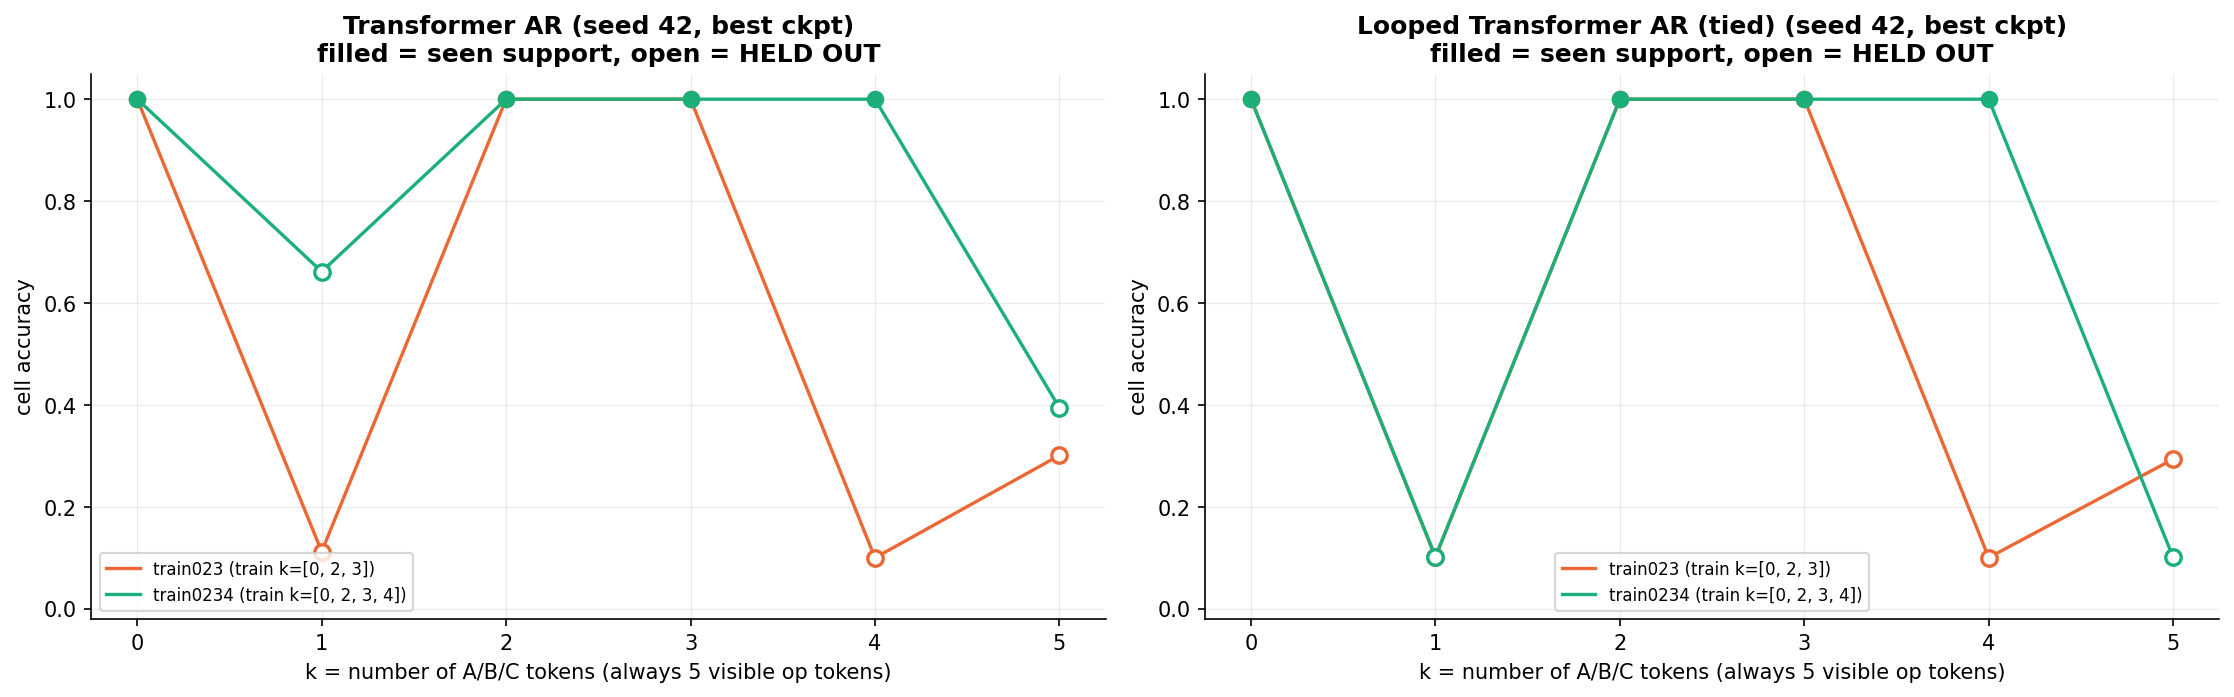

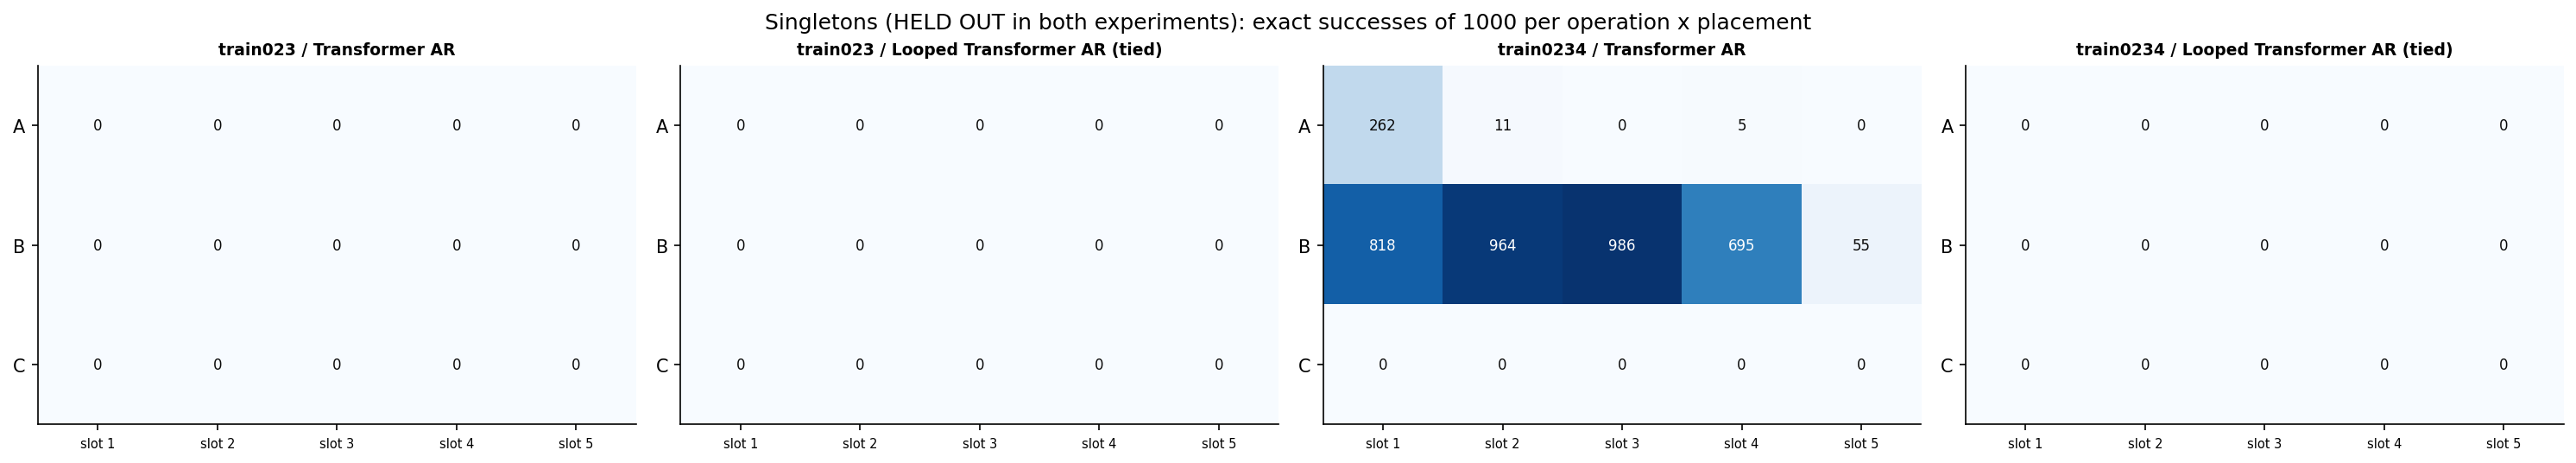

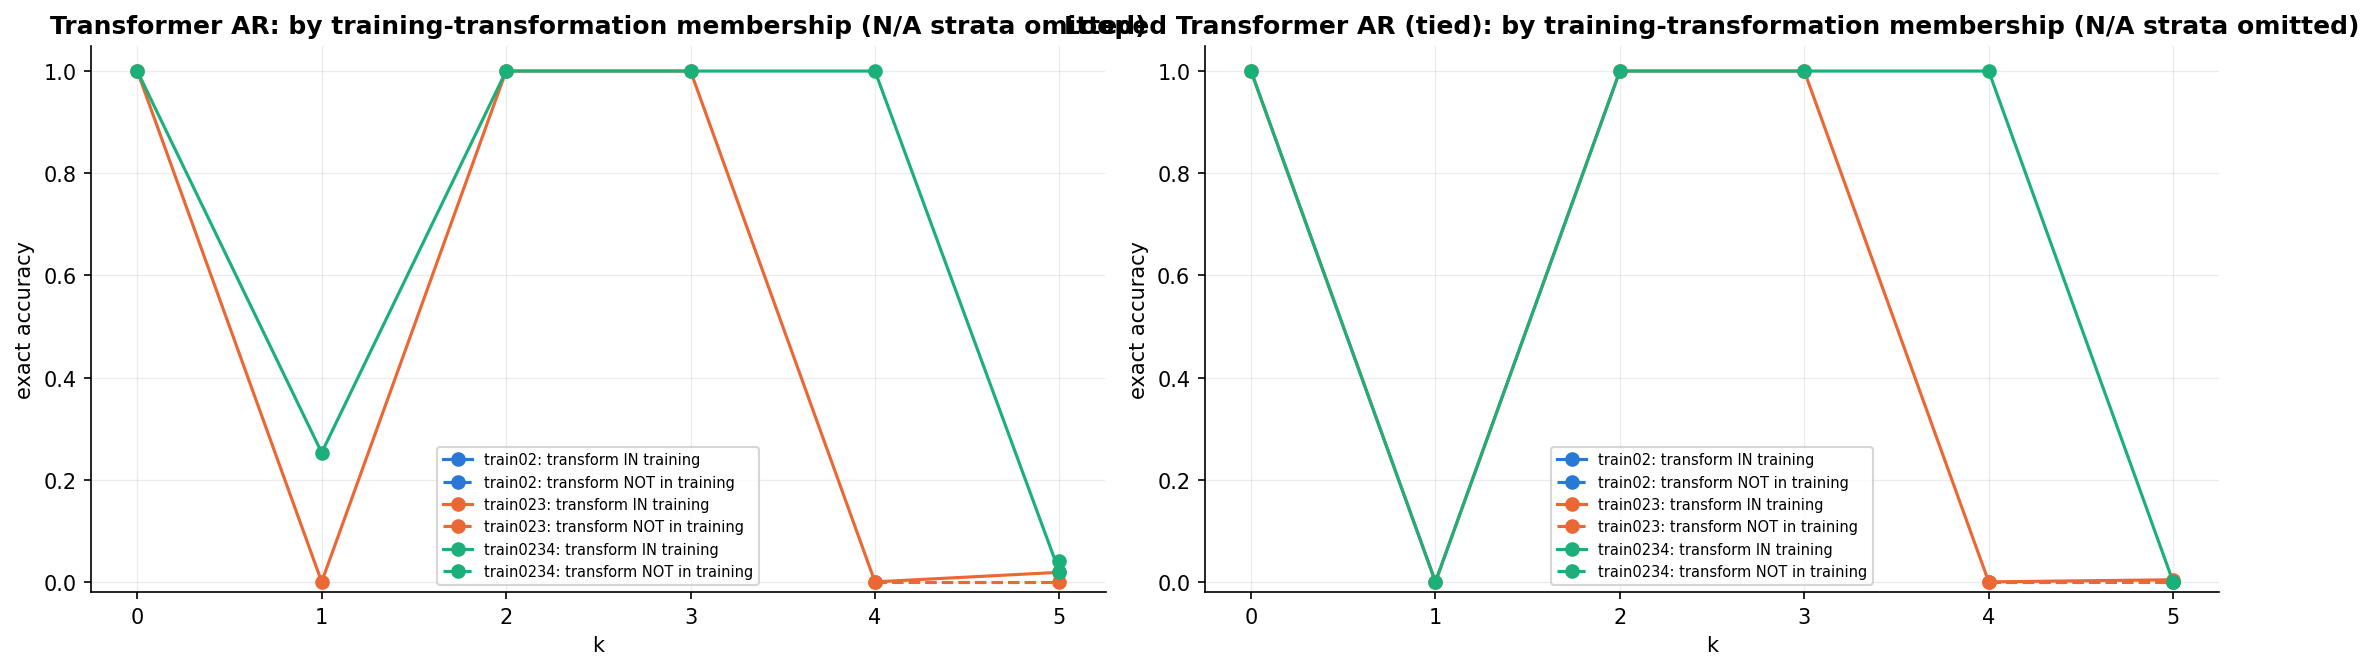

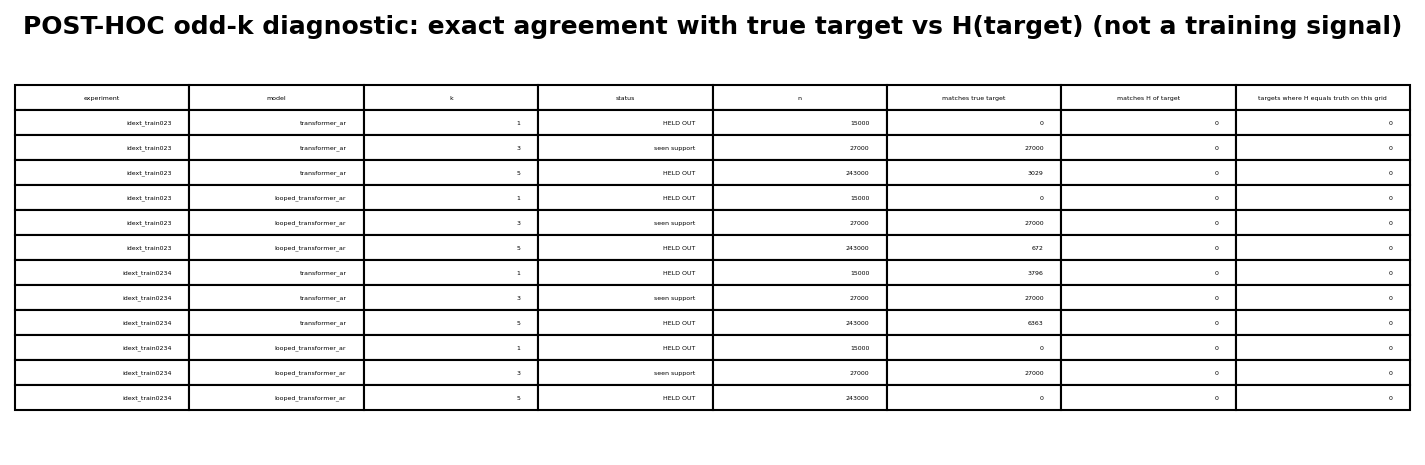

,experiment,model,status
0,idext_train02,transformer_ar,not yet available
1,idext_train02,looped_transformer_ar,not yet available
2,idext_train023,transformer_ar,analysed
3,idext_train023,looped_transformer_ar,analysed
4,idext_train0234,transformer_ar,analysed
5,idext_train0234,looped_transformer_ar,analysed


,experiment,model,k,exact_correct,n,exact_acc,cell_acc,invalid_rate,status
0,idext_train023,transformer_ar,0,1000,1000,1.000000,1.000000,0.000000,seen support
1,idext_train023,transformer_ar,1,0,15000,0.000000,0.112524,0.000267,HELD OUT
2,idext_train023,transformer_ar,2,9000,9000,1.000000,1.000000,0.000000,seen support
3,idext_train023,transformer_ar,3,27000,27000,1.000000,1.000000,0.000000,seen support
4,idext_train023,transformer_ar,4,0,81000,0.000000,0.100245,0.000000,HELD OUT
5,idext_train023,transformer_ar,5,3029,243000,0.012465,0.301111,0.000000,HELD OUT
6,idext_train023,looped_transformer_ar,0,1000,1000,1.000000,1.000000,0.000000,seen support
7,idext_train023,looped_transformer_ar,1,0,15000,0.000000,0.101570,0.000000,HELD OUT
8,idext_train023,looped_transformer_ar,2,9000,9000,1.000000,1.000000,0.000000,seen support
9,idext_train023,looped_transformer_ar,3,27000,27000,1.000000,1.000000,0.000000,seen support


,experiment,model,string,position,exact_correct,n,exact_acc,cell_acc
0,idext_train023,transformer_ar,A,1,0,1000,0.000,0.088889
1,idext_train023,transformer_ar,A,2,0,1000,0.000,0.102000
2,idext_train023,transformer_ar,A,3,0,1000,0.000,0.106222
3,idext_train023,transformer_ar,A,4,0,1000,0.000,0.105944
4,idext_train023,transformer_ar,A,5,0,1000,0.000,0.108778
5,idext_train023,transformer_ar,B,1,0,1000,0.000,0.143500
6,idext_train023,transformer_ar,B,2,0,1000,0.000,0.143972
7,idext_train023,transformer_ar,B,3,0,1000,0.000,0.136750
8,idext_train023,transformer_ar,B,4,0,1000,0.000,0.135056
9,idext_train023,transformer_ar,B,5,0,1000,0.000,0.121194


,experiment,model,op,n_grids,grids_identical_across_5_placements,rate
0,idext_train023,transformer_ar,A,1000,0,0.00
1,idext_train023,transformer_ar,B,1000,0,0.00
2,idext_train023,transformer_ar,C,1000,1000,1.00
3,idext_train023,looped_transformer_ar,A,1000,0,0.00
4,idext_train023,looped_transformer_ar,B,1000,0,0.00
5,idext_train023,looped_transformer_ar,C,1000,1000,1.00
6,idext_train0234,transformer_ar,A,1000,0,0.00
7,idext_train0234,transformer_ar,B,1000,60,0.06
8,idext_train0234,transformer_ar,C,1000,1000,1.00
9,idext_train0234,looped_transformer_ar,A,1000,0,0.00


,experiment,model,k,transform_in_training,exact_correct,n,exact_acc
0,idext_train023,transformer_ar,0,True,1000,1000,1.000000
1,idext_train023,transformer_ar,0,False,0,0,NaN
2,idext_train023,transformer_ar,1,True,0,15000,0.000000
3,idext_train023,transformer_ar,1,False,0,0,NaN
4,idext_train023,transformer_ar,2,True,9000,9000,1.000000
5,idext_train023,transformer_ar,2,False,0,0,NaN
6,idext_train023,transformer_ar,3,True,27000,27000,1.000000
7,idext_train023,transformer_ar,3,False,0,0,NaN
8,idext_train023,transformer_ar,4,True,0,38000,0.000000
9,idext_train023,transformer_ar,4,False,0,43000,0.000000


,experiment,model,k,n,status,matches_true_target,matches_H_of_target,targets_where_H_equals_truth_on_this_grid,matches_both (ambiguous)
0,idext_train023,transformer_ar,1,15000,HELD OUT,0,0,0,0
1,idext_train023,transformer_ar,3,27000,seen support,27000,0,0,0
2,idext_train023,transformer_ar,5,243000,HELD OUT,3029,0,0,0
3,idext_train023,looped_transformer_ar,1,15000,HELD OUT,0,0,0,0
4,idext_train023,looped_transformer_ar,3,27000,seen support,27000,0,0,0
5,idext_train023,looped_transformer_ar,5,243000,HELD OUT,672,0,0,0
6,idext_train0234,transformer_ar,1,15000,HELD OUT,3796,0,0,0
7,idext_train0234,transformer_ar,3,27000,seen support,27000,0,0,0
8,idext_train0234,transformer_ar,5,243000,HELD OUT,6363,0,0,0
9,idext_train0234,looped_transformer_ar,1,15000,HELD OUT,0,0,0,0


,pair,model,k,status,status_A,status_B,n,A_exact,B_exact,both_correct,only_A_correct,only_B_correct,both_wrong
0,train02 vs train023,transformer_ar,all,not yet available,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,train02 vs train023,looped_transformer_ar,all,not yet available,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,train02 vs train0234,transformer_ar,all,not yet available,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,train02 vs train0234,looped_transformer_ar,all,not yet available,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,train023 vs train0234,transformer_ar,0,NaN,seen,seen,1000.0,1000.0,1000.0,1000.0,0.0,0.0,0.0
5,train023 vs train0234,transformer_ar,1,NaN,HELD OUT,HELD OUT,15000.0,0.0,3796.0,0.0,0.0,3796.0,11204.0
6,train023 vs train0234,transformer_ar,2,NaN,seen,seen,9000.0,9000.0,9000.0,9000.0,0.0,0.0,0.0
7,train023 vs train0234,transformer_ar,3,NaN,seen,seen,27000.0,27000.0,27000.0,27000.0,0.0,0.0,0.0
8,train023 vs train0234,transformer_ar,4,NaN,HELD OUT,seen,81000.0,0.0,81000.0,0.0,0.0,81000.0,0.0
9,train023 vs train0234,transformer_ar,5,NaN,HELD OUT,HELD OUT,243000.0,3029.0,6363.0,0.0,3029.0,6363.0,233608.0


In [7]:
# --- Curves, per-k results, singletons, transformation coverage, H diagnostic, paired transitions ---------------
# (rerun this cell alone after both notebooks finish to get the full joint comparison; no retraining)
from decompositionality.reports import plot_training_curves
from decompositionality.mixed_reports import plot_length_curves
from decompositionality.idext_reports import analyse_all, plot_main, plot_singletons, plot_transform_split_and_h, status_table
paths = (plot_training_curves(cfg.experiment_dir, cfg.experiment_dir / "figures") or []) + \
        (plot_length_curves(cfg.experiment_dir, cfg.experiment_dir / "figures") or [])
res = analyse_all(FAMILY_ROOT, SEED)
FIG = res["out"] / "figures"
paths += plot_main(res, FIG) + plot_singletons(res, FIG) + plot_transform_split_and_h(res, FIG)
for p in paths:
    if str(p).endswith(".png"):
        display(Image(filename=str(p)))
display(res["status"]); display(res["by_k"]); display(res["singletons"]); display(res["consistency"])
display(res["transform_split"]); display(res["h_agreement"]); display(res["paired"])


In [8]:
# --- Export + per-run status (complete only if BOTH models are trained and evaluated) ---------------------------
from decompositionality.mixed_reports import make_compact_archive
st = status_table(FAMILY_ROOT, SEED); display(st)
mine = st[st.experiment == EXPERIMENT]
make_compact_archive(cfg.experiment_dir)
print("COMPLETE" if (mine.trained.all() and mine.evaluated.all()) else
      f"INCOMPLETE: {mine[~(mine.trained & mine.evaluated)].model.tolist()} -> rerun Run all to resume")


,experiment,model,trained,evaluated,records,selected_step
0,idext_train02,transformer_ar,False,False,NaN,NaN
1,idext_train02,looped_transformer_ar,False,False,NaN,NaN
2,idext_train023,transformer_ar,True,True,376000.0,5000.0
3,idext_train023,looped_transformer_ar,True,True,376000.0,5000.0
4,idext_train0234,transformer_ar,True,True,376000.0,5000.0
5,idext_train0234,looped_transformer_ar,True,True,376000.0,4750.0


Compact archive: /content/drive/MyDrive/decompositionality_results/identity_ar_count_extrapolation/train0234/seed_42/results_seed_42.zip (18.4 MiB)
COMPLETE


In [9]:
from google.colab import runtime

runtime.unassign()

Outputs: `<RESULTS_ROOT>/identity_ar_count_extrapolation/` -> `manifests/`, `train02/seed_42/<model>`, `train023/seed_42/<model>` (runs, eval + ARTIFACT.json, audits), `artifact_index.json`, `comparisons/seed_42/` (tables + figures).